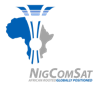 &nbsp;&nbsp; 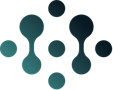

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-6/day-3-project-clinic-and-demo-day/2-exercise/W6D3-exercise.ipynb)

# 🎤 Week 6 · Day 3: Project Self-Check

**Today:** you play the reviewer. A colleague, **Ada**, has a draft project with problems planted in it. You find them with six small self-check functions, fix them, then rehearse the deployment and the last minute of your demo.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

### Two ways to use this notebook
1. **In Colab, today:** Parts A–D rehearse on Ada's export, which is built from a **synthetic** course file. Safe for Colab.
2. **On the training server, for your project:** **File → Download → Download .ipynb**, open it on the server, and fill in **Part E** with your real data.

> 🔒 **Real NIGCOMSAT data never goes into Colab or into an AI tool** (unless your unit head agreed in writing). Part E is for the training server only.

**Rule book:** keep `W6D3-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def plant_problems(tickets):
    """Ada's export: the real weekly tickets with two problems planted, like a real NOC export."""
    draft = tickets.drop(pd.Timestamp("2025-03-10"))                                   # one week never arrived
    draft = pd.concat([draft, draft.loc[[pd.Timestamp("2025-06-16")]]]).sort_index()   # one week exported twice
    return draft

def ready(*names):
    """True when every name exists (the earlier task is done); otherwise says what to finish first."""
    missing = [n for n in names if globals().get(n) is None]
    if missing:
        print(f"✍️  Finish the task that makes {', '.join(missing)} first, then run this cell again.")
    return not missing

def _words(s, n):
    return isinstance(s, str) and len(s.split()) >= n

def _c_a1(x):
    return str(x).strip().upper() == "W-MON", \
        "W-MON: weekly, on Mondays. Now read the report: two ⚠️ lines. 🔎", \
        "Weekly on Mondays is written \"W-MON\" (with the dash)."

def _c_a2(x):
    return tuple(int(v) for v in x) == (1, 1), \
        "One week exported twice, one week that never arrived. Real exports do this all the time. 👯🏾🕳️", \
        "Read the two ⚠️ lines: duplicate timestamps first, then missing timestamps."

def _c_a3(x):
    if not isinstance(x, pd.DataFrame):
        return False, "", "Run the cell with GAP_FILL filled in."
    v = float(x.loc[pd.Timestamp("2025-03-10"), "tickets_raised"])
    ok = (len(x) == 104 and x.index.is_unique and x.index.freq is not None and x.index.freqstr == "W-MON"
          and int(x.isna().sum().sum()) == 0 and abs(v - 50.0) < 1e-9)
    hint = ("0 tickets is a week that never happened: it drags every forecast down. Use \"interpolate\"."
            if v == 0 else "GAP_FILL = \"interpolate\": the lost week becomes the average of the weeks either side.")
    return ok, f"Clean: 104 weeks, no repeats, no holes, frequency declared. The lost week (2025-03-10) became {v:.0f}, between its neighbours 48 and 52. Write that in your report. 🧹", hint

def _c_a4(x):
    return int(x[0]) == 1 and x[1] is True, \
        "shift(1): the 4 weeks BEFORE this one. The leak test says honest. 🛡️", \
        "shift(1) moves every value one week later, so week t only sees weeks t-4 to t-1. Then leak_test must say True."

def _c_b1(x):
    return tuple(int(v) for v in x) == (96, 8), \
        "96 training weeks, 8 test weeks (3 Nov to 22 Dec 2025), and the assert passed. ✂️", \
        "CUT = \"2025-11-03\": the first test week. Train = the weeks before it, test = from it on."

def _c_b2(x):
    ok = isinstance(x, pd.DataFrame) and x.index[0] == 'rate seasonal naive' and abs(float(x.iloc[0, 0]) - 2.2393239542193557) < 1e-6
    return ok, "Same 8 weeks, same scorer: the rate seasonal naive wins with MAE 2.24. That's the table your demo needs. 📊", \
        "TERMINALS = train[\"active_vsat_terminals\"]: the training weeks' network size."

def _c_b3(x):
    return abs(float(x) - 0.75) < 1e-9, \
        "Ada's “90%” band caught 6 of 8 weeks. Too narrow for a 90% claim. 📏", \
        "coverage(test_y, fc - 3, fc + 3)"

def _c_b4(x):
    q, cov = x
    return abs(float(q) - 0.9) < 1e-9 and abs(float(cov) - 1.0) < 1e-9, \
        "The 90th-percentile past miss is ±7.0 tickets, and that band caught 8 of 8 held-out weeks. Honest. ✅", \
        "For a 90% band, take the 90% quantile of the past misses: 0.9"

def _c_c1(x):
    from pathlib import Path as _P
    ok = (isinstance(x, (list, tuple)) and len(x) == 2 and all(_P(p).exists() and "2025-12-22" in _P(p).name for p in x)
          and "about 65 tickets" in _P(x[1]).read_text(encoding="utf-8"))
    return ok, "A dated chart and a dated summary. On the server, cron writes a new pair every morning. 🗓️", \
        "STAMP_FORMAT = \"%Y-%m-%d\": year first, so the files sort by date."

def _c_c2(x):
    return " ".join(str(x).split()) == '0 7 * * *', \
        "0 7 * * *: minute 0, hour 7, every day, every month, every weekday. Your report is ready before the 8:00 meeting. ⏰", \
        "Five fields: minute, hour, day of month, month, day of week. A star means every. 07:00 daily = \"0 7 * * *\""

def _c_d1(x):
    ok = len(x) == 4 and all(_words(s, 4) for s in x) and any(ch.isdigit() for ch in x[1])
    hint = ("Put ONE number from the evaluation in the Observation sentence."
            if len(x) == 4 and all(_words(s, 4) for s in x) else "Write all four sentences, each at least 4 words.")
    return ok, "Four sentences, one number, one action. That's how your demo ends. 🗣️", hint

def _c_d2(x):
    return len(x) == 3 and all(_words(s, 3) for s in x), \
        "Three honest limits: what it misses, how far it reaches, what you called normal. Unit heads trust this. 🧭", \
        "Answer all three, each in a short sentence (at least 3 words)."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4,
          "C1": _c_c1, "C2": _c_c2, "D1": _c_d1, "D2": _c_d2}
HINTS = {"A2": "Two whole numbers: (duplicates, missing).", "B4": "Two things: the quantile (0.9) and the coverage the cell computes.",
         "D1": "Four sentences, as text in quotes."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


### ▶️ Your self-check toolkit
Six small functions. Read them once: they're short on purpose, so you can copy them into your own project.

| Function | The question it answers |
|---|---|
| `hygiene(df, freq)` | Is the series clean: time index, in order, no repeats, no holes, frequency declared, time zone known? |
| `leak_test(make_feature, df)` | Could this feature have been computed before the week started? |
| `check_temporal_split(train_index, test_index, embargo)` | Is every training timestamp before every test timestamp, with a gap? |
| `compare(actual, forecasts)` | Same weeks, same scorer: which method wins? |
| `coverage(actual, lower, upper)` | Did the band catch the share it promised? |
| `recommendation(...)` | Are the 4 sentences there, with a number? |

In [ ]:
def naive(series, h):
    """Grandma's forecast: the last value we saw, repeated h times."""
    return np.full(h, float(series.iloc[-1]))

def seasonal_naive(series, h, period=52):
    """The same weeks one season (52 weeks) ago."""
    last_season = series.iloc[-period:].values
    return np.tile(last_season, int(np.ceil(h / period)))[:h].astype(float)

def rate_seasonal_naive(series, terminals, h, period=52):
    """Grandma, adjusted for the bigger family: last year's tickets PER TERMINAL x today's terminals."""
    rate = series / terminals
    return rate.iloc[-period:].values[:h] * float(terminals.iloc[-1])

def mae(forecast, actual):
    """Mean absolute error: on a typical week, how many tickets were we off by?"""
    return float(np.mean(np.abs(np.asarray(forecast, float) - np.asarray(actual, float))))

def rate_past_errors(df, origin, h=8, period=52):
    """Misses of every h-week rate forecast made from an earlier origin whose h weeks end before `origin`."""
    errors = []
    for o in range(period, origin - h + 1):
        f = rate_seasonal_naive(df["tickets_raised"].iloc[:o], df["active_vsat_terminals"].iloc[:o], h, period)
        errors.extend(df["tickets_raised"].iloc[o:o + h].values - f)
    return np.array(errors)

def hygiene(df, freq):
    """Stage 1 self-check: index, order, duplicates, gaps, declared frequency, time zone, empty cells."""
    idx = df.index
    is_dt = isinstance(idx, pd.DatetimeIndex)
    report = {"rows": len(df),
              "datetime index": is_dt,
              "sorted in time": bool(idx.is_monotonic_increasing),
              "duplicate timestamps": int(idx.duplicated().sum()),
              "missing timestamps": len(pd.date_range(idx.min(), idx.max(), freq=freq).difference(idx)) if is_dt else None,
              "frequency declared": idx.freqstr if is_dt and idx.freq is not None else None,
              "time zone": str(idx.tz) if is_dt and idx.tz is not None else "not stored: write it in your report",
              "empty cells": int(df.isna().sum().sum())}
    want = {"datetime index": True, "sorted in time": True, "duplicate timestamps": 0, "missing timestamps": 0, "empty cells": 0}
    for k, v in report.items():
        if k in want:
            mark = "✅" if v == want[k] else "⚠️"
        elif k == "frequency declared":
            mark = "✅" if v else "⚠️"
        else:
            mark = "  "
        print(f"{mark} {k:22s} {v}")
    return report

def leak_test(make_feature, df, target="tickets_raised", n_checks=12):
    """The leak test, done by the computer. For several weeks t: hide the target at t and EVERY row after t,
    rebuild the feature, and compare its value at t. If it changes, the feature used something you couldn't know."""
    full = make_feature(df)
    for t in np.linspace(len(df) // 4, len(df) - 2, n_checks).astype(int):
        hidden = df.astype(float)
        hidden.iloc[t + 1:] = np.nan
        hidden.iloc[t, hidden.columns.get_loc(target)] = np.nan
        a, b = full.iloc[t], make_feature(hidden).iloc[t]
        if not ((pd.isna(a) and pd.isna(b)) or (not pd.isna(b) and np.isclose(a, b))):
            return False
    return True

def check_temporal_split(train_index, test_index, embargo="0D"):
    """Stage 3 rule 1: every training timestamp comes BEFORE every test timestamp, with a gap longer than the embargo."""
    last_train, first_test = pd.Index(train_index).max(), pd.Index(test_index).min()
    assert last_train < first_test, (f"❌ not a split by time: training reaches {last_train:%d %b %Y} "
                                     f"but the test starts {first_test:%d %b %Y}")
    gap = first_test - last_train
    assert gap > pd.Timedelta(embargo), f"❌ embargo too short: the gap is {gap}, it must be more than {embargo}"
    print(f"✅ split by time: training ends {last_train:%d %b %Y}, the test starts {first_test:%d %b %Y}")
    return gap

def compare(actual, forecasts, scorer=None):
    """Stage 3 rule 2: every method on the SAME weeks, with the SAME scorer. Returns a table, best first."""
    scorer = scorer or mae
    scores = {}
    for name, f in forecasts.items():
        f = np.asarray(f, float)
        assert len(f) == len(actual), f"❌ {name} has {len(f)} forecasts but the test has {len(actual)} weeks: not the same period"
        scores[name] = scorer(f, actual)
    return pd.Series(scores, name=scorer.__name__).sort_values().to_frame()

def coverage(actual, lower, upper):
    """Share of the real values that landed inside the band. A 90% band should score about 0.9 on held-out data."""
    a = np.asarray(actual, float)
    return float(np.mean((a >= np.asarray(lower, float)) & (a <= np.asarray(upper, float))))

def recommendation(situation, observation, implication, action):
    """The 4-sentence recommendation for your unit head. The observation must carry a number."""
    parts = {"Situation": situation, "Observation": observation, "Implication": implication, "Recommendation": action}
    for k, v in parts.items():
        print(f"{k:>15}: {str(v).strip()}")
    return " ".join(str(v).strip().rstrip(".") + "." for v in parts.values())

print("✅ self-check toolkit and the Week 5–6 forecasting tools are ready")

---
# Part A: Data & leaks (clinic station 1) 🔎

📖 Ada exported two years of weekly NOC tickets from the "NOC system". Real exports are messy: weeks go missing, weeks get exported twice. This one has **two** planted problems.

▶️ Load Ada's export exactly as it arrived (no `.asfreq()` yet).

In [ ]:
raw = pd.read_csv(data_path("ops_tickets_weekly"), parse_dates=["week_start"], index_col="week_start")
draft = plant_problems(raw)          # Ada's export: the real file + 2 planted problems
print("rows in Ada's export:", len(draft))
draft.head()

### A1 ✍️ Run the hygiene report
`hygiene()` needs the frequency the series **should** have. Ticket weeks start on Mondays. Type the pandas frequency for "weekly, on Mondays", as text.

In [ ]:
FREQ = ___

report = hygiene(draft, FREQ) if FREQ else None
check("A1", FREQ)

### A2 ✍️ What did the report find?
Read the two ⚠️ lines. How many **duplicate** timestamps, and how many **missing** timestamps? Two whole numbers.

In [ ]:
n_duplicates = ___
n_missing = ___

check("A2", (n_duplicates, n_missing))

### A3 ✍️ Fix the export
The cell drops the repeated week, puts time in order and declares the frequency. Declaring it makes the lost week appear as an **empty** row. You choose how to fill it:
- `"interpolate"`: the average of the weeks either side
- `"zero"`: pretend the NOC raised 0 tickets that week

Whichever you choose, your report must **say what you did**.

In [ ]:
GAP_FILL = ___

clean = None
if GAP_FILL:
    clean = draft[~draft.index.duplicated(keep="first")].sort_index().asfreq("W-MON")
    clean = clean.interpolate() if GAP_FILL == "interpolate" else clean.fillna(0)
    hygiene(clean, "W-MON")
check("A3", clean)

### ▶️ The leak test, done by the computer
📖 The question from Week 5: *"Could I have computed this feature at the moment the forecast was needed?"* `leak_test()` asks it for you. For several weeks it **hides that week's answer and every row after it**, rebuilds the feature, and checks whether the value changed. If it changed, the feature used something you couldn't have known.

▶️ Six suspects, on the clean file.

In [ ]:
SUSPECTS = {
    "last week: shift(1)": lambda d: d["tickets_raised"].shift(1),
    "same week last year: shift(52)": lambda d: d["tickets_raised"].shift(52),
    "terminals this week": lambda d: d["active_vsat_terminals"],
    "next week: shift(-1)": lambda d: d["tickets_raised"].shift(-1),
    "4-week mean, centred": lambda d: d["tickets_raised"].rolling(4, center=True).mean(),
    "4-week mean, including this week": lambda d: d["tickets_raised"].rolling(4).mean(),
}

if ready("clean"):
    for name, make in SUSPECTS.items():
        print(f"{'✅ honest' if leak_test(make, clean) else '🚨 LEAKS '}   {name}")

### A4 ✍️ Fix the leaky 4-week mean
`rolling(4).mean()` on its own includes **this** week: the very number you're trying to forecast. Shift it so week *t* only sees the 4 weeks **before** it. How many weeks do you shift by?

In [ ]:
SHIFT = ___

passed = None
if SHIFT is not None and ready("clean"):
    past_4_weeks = lambda d: d["tickets_raised"].rolling(4).mean().shift(SHIFT)
    passed = leak_test(past_4_weeks, clean)
    print("leak test:", "✅ honest" if passed else "🚨 still leaks")
check("A4", (SHIFT, passed))

---
# Part B: The honest test (clinic station 2) ⚖️

▶️ Ada split her weeks **at random** ("everyone does `train_test_split`!"). Watch `check_temporal_split()` catch it.

In [ ]:
if ready("clean"):
    shuffled = clean.sample(frac=1, random_state=7)       # Ada's random split
    ada_train, ada_test = shuffled.iloc[:-8], shuffled.iloc[-8:]
    try:
        check_temporal_split(ada_train.index, ada_test.index)
    except AssertionError as e:
        print(e)
        print("👆 That is why it fails: the test weeks are mixed in with the training weeks.")

### B1 ✍️ Split by time instead
Keep the **last 8 weeks** for the test, like Week 5 Day 2. The first test week is **3 November 2025**. Type it as text, like `"2025-01-01"`.

In [ ]:
CUT = ___

split = None
if CUT and ready("clean"):
    train = clean[clean.index < CUT]
    test = clean[clean.index >= CUT]
    test_y = test["tickets_raised"]
    check_temporal_split(train.index, test.index)
    split = (len(train), len(test))
    print("training weeks:", len(train), "· test weeks:", len(test))
check("B1", split)

### B2 ✍️ The comparison table: same weeks, same scorer
`compare()` scores every forecast on the **same 8 test weeks** with the **same scorer** (MAE), best first. It refuses a forecast for a different number of weeks.
The rate seasonal naive (Week 5 Day 2) needs the training weeks' **terminal counts**. Fill them in.

In [ ]:
TERMINALS = ___

table = None
if TERMINALS is not None and ready("train", "test_y"):
    ty = train["tickets_raised"]
    table = compare(test_y, {"naive": naive(ty, 8), "seasonal naive": seasonal_naive(ty, 8),
                             "rate seasonal naive": rate_seasonal_naive(ty, TERMINALS, 8)})
    display(table)
check("B2", table)

### B3 ✍️ Ada's "90%" band
Ada put **±3 tickets** around the rate forecast "because it looked tidy", and called it a 90% band. What share of the 8 test weeks did it actually catch? Use `coverage(actual, lower, upper)`.

In [ ]:
fc = rate_seasonal_naive(train["tickets_raised"], train["active_vsat_terminals"], 8) if ready("train") else None

cov_ada = ___

if cov_ada is not None:
    print(f"Ada's band caught {cov_ada:.0%} of the test weeks")
check("B3", cov_ada)

### B4 ✍️ The honest band (Week 5 Day 3's recipe)
Make the same 8-week forecast from every **earlier** week, record every miss, and use the miss you beat 90% of the time as the half-width. Which quantile gives a 90% band?

In [ ]:
Q = ___

result = None
if Q is not None and ready("train", "fc"):
    misses = rate_past_errors(clean, len(train), h=8)
    half = np.quantile(np.abs(misses), Q)
    cov_honest = coverage(test_y, fc - half, fc + half)
    print(f"{len(misses)} past misses · half-width ±{half:.1f} tickets · caught {cov_honest:.0%} of the test weeks")
    result = (Q, cov_honest)
check("B4", result)

---
# Part C: Deployment (clinic station 3) 🚀

📖 Your tool must **run on the training server**, not only on your laptop. Two options:
- a **scheduled report**: a script the server runs every morning, writing a dated chart and summary to a shared folder
- a **Streamlit dashboard**: a small web page your unit opens in a browser

▶️ Here is a scheduled report for the ticket forecast. Read it: it forecasts the week after the data ends, with its honest band, and saves two dated files.

In [ ]:
from pathlib import Path
from IPython.display import Image

def write_report(df, stamp_format, out_dir="reports"):
    """A scheduled report: one dated chart + one dated summary for the week after the data ends.
    On the training server, cron runs this every morning, so nobody has to remember."""
    y, term = df["tickets_raised"], df["active_vsat_terminals"]
    forecast = rate_seasonal_naive(y, term, 1)[0]
    misses = rate_past_errors(df, len(df), h=1)
    half = float(np.quantile(np.abs(misses), 0.9))
    next_week = df.index[-1] + pd.Timedelta("7D")
    stamp = df.index[-1].strftime(stamp_format)
    out = Path(out_dir)
    out.mkdir(exist_ok=True)
    fig, ax = plt.subplots()
    ax.plot(y.index, y.values, label="tickets per week")
    ax.errorbar([next_week], [forecast], yerr=[[half], [half]], fmt="o", capsize=6, label="next week, 90% band")
    ax.set_title(f"Next week: about {forecast:.0f} tickets, plausibly {forecast - half:.0f} to {forecast + half:.0f}")
    ax.set_ylabel("tickets per week")
    ax.legend(loc="upper left")
    fig.tight_layout()
    png = out / f"ticket-report-{stamp}.png"
    fig.savefig(png, dpi=100)
    plt.close(fig)
    txt = out / f"ticket-report-{stamp}.txt"
    txt.write_text(f"Week of {next_week:%d %b %Y}: about {forecast:.0f} tickets, plausibly {forecast - half:.0f} "
                   f"to {forecast + half:.0f} (90% band from {len(misses)} past one-week forecasts). "
                   "Method: last year's tickets per terminal x this week's terminals.\n", encoding="utf-8")
    return [str(png), str(txt)]

print("✅ write_report() is ready")

### C1 ✍️ Name the files by date
Every morning's report needs its own file name. Choose a date format so the files **sort in date order** in the folder. Python's codes: `%Y` = year, `%m` = month, `%d` = day.

In [ ]:
STAMP_FORMAT = ___

paths = None
if STAMP_FORMAT and ready("clean"):
    paths = write_report(clean, STAMP_FORMAT)
    print(paths)
    print(Path(paths[1]).read_text())
    display(Image(paths[0]))
check("C1", paths)

### C2 ✍️ Schedule it
On the training server (Linux), **cron** runs a command on a timetable. A cron line has **five** fields, then the command:

```
minute  hour  day-of-month  month  day-of-week   command
```

A `*` means "every". Write the five fields for **07:00 every day**, as text.

In [ ]:
CRON_TIME = ___

if CRON_TIME:
    print("crontab line:", CRON_TIME, "cd /home/me/project && python report.py")
check("C2", CRON_TIME)

### ▶️ Or a Streamlit dashboard
This writes a starter `app.py` (Files panel 📁 → right-click → Download). On the server: `pip install streamlit`, then `streamlit run app.py`. Streamlit doesn't run inside Colab, so this cell only writes the file.

In [ ]:
APP = '''import pandas as pd
import streamlit as st

# Run on the training server:  streamlit run app.py
# Real data is read from a path on the server (set in .env or a config file), never from Git.
DATA = "/data/my_unit/export.csv"
THRESHOLD = 80.0

st.title("My unit's monitor")
df = pd.read_csv(DATA, parse_dates=["timestamp"], index_col="timestamp")
st.line_chart(df["value"])
st.write(f"Threshold: {THRESHOLD}")
st.write("One paragraph in plain words: what the chart shows, the latest forecast or flags with their range, and what to do.")'''
Path("app.py").write_text(APP, encoding="utf-8")
print(APP)

---
# Part D: The story (clinic station 4) 🗣️

📖 Your demo ends with the 4-sentence recommendation, and your report states three limitations. Rehearse both on the ticket forecast, using the numbers from Week 6 Day 1's backtest:

| From the Week 6 Day 1 backtest (45 starting weeks, 8 weeks ahead) | MAE (tickets per week) |
|---|---|
| Rate seasonal naive: last year's tickets per terminal × this week's terminals | **3.18** |
| Naive: "same as last week" | 6.20 |
| The regression | can only forecast 1 week ahead (it needs last week's real count) |

### D1 ✍️ Write the 4 sentences
1. **Situation:** what the unit does today, and the problem.
2. **Observation:** what the evaluation showed: **one number**.
3. **Implication:** what it means for operations.
4. **Recommendation:** what to do next, and with which tool.

In [ ]:
situation = ___
observation = ___
implication = ___
action = ___

if None not in (situation, observation, implication, action):
    text = recommendation(situation, observation, implication, action)
check("D1", (situation, observation, implication, action))

### D2 ✍️ Three honest limitations
Answer each in one short sentence.

In [ ]:
what_it_misses = ___
how_late_or_far = ___
what_was_normal = ___

check("D2", (what_it_misses, how_late_or_far, what_was_normal))

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

---
# Part E: On your own project (training server only) 🔒

📖 Download this notebook (**File → Download → Download .ipynb**) and open it on the **training server**. Fill in the five settings below. While `PROJECT_CSV` is `None`, every cell here politely skips, so the notebook still runs in Colab.

> 🔒 Never put real NIGCOMSAT data in Colab, an AI tool or GitHub.

In [ ]:
PROJECT_CSV = None        # e.g. "/data/my_unit/battery_export.csv" (a path on the server)
TIME_COL = None           # e.g. "timestamp"
VALUE_COL = None          # e.g. "battery_capacity_pct"
PROJECT_FREQ = None       # e.g. "h", "D" or "W-MON"
THRESHOLD = None          # your operational limit, e.g. 80.0 (or None)

mine = None
if PROJECT_CSV is None:
    print("⏭️  Skipped: set PROJECT_CSV on the training server to check your own data.")
else:
    mine = pd.read_csv(PROJECT_CSV, parse_dates=[TIME_COL], index_col=TIME_COL).sort_index()
    hygiene(mine, PROJECT_FREQ)

In [ ]:
if mine is None:
    print("⏭️  Skipped: no project data loaded.")
else:
    ax = mine[VALUE_COL].plot(title="✍️ Write a title that states your finding")
    if THRESHOLD is not None:
        ax.axhline(THRESHOLD, color="#E5484D", ls="--", label=f"threshold {THRESHOLD}")
        ax.legend()
    plt.show()

In [ ]:
# Your split: set the first test timestamp and your longest feature window (the embargo)
PROJECT_CUT = None        # e.g. "2025-09-01"
PROJECT_EMBARGO = "0D"    # e.g. "24h" for a 24-hour rolling window

if mine is None or PROJECT_CUT is None:
    print("⏭️  Skipped: set PROJECT_CUT once your data is loaded.")
else:
    my_train = mine[mine.index < PROJECT_CUT]
    my_test = mine[mine.index >= pd.Timestamp(PROJECT_CUT) + pd.Timedelta(PROJECT_EMBARGO)]
    check_temporal_split(my_train.index, my_test.index, PROJECT_EMBARGO)

### 📝 Before you present
- **Hygiene:** no repeats, no holes (or holes explained), frequency declared, time zone written down.
- **Leak test:** every feature passes `leak_test()`.
- **Honest test:** split by time with the assert, the baseline on the same period with the same scorer, and the spread (folds), the repeated calls (remaining life) or the coverage (bands).
- **Deployed:** it runs on the training server; the README says how.
- **The story:** 4 sentences with one number, 3 limitations, and a 5-minute run-through with a timer.

**Congratulations: that's the course.** 🎉 Go and show your unit what you built.

<sub>Data: the synthetic `ops_tickets_weekly.csv` from the original Week 6 code book (`Time-series/week-06`), with two problems planted for the rehearsal. Safe to use with AI tools; real NIGCOMSAT data is not.</sub>